<a href="https://colab.research.google.com/github/boluwatiseoyetunji-rgb/G5_Mindspire_Stemnestacademy/blob/main/Setup_plus_first_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

print("scikit-learn is ready")

scikit-learn is ready


In [ ]:
complaints = [
    "I can't log in to my account",
    "My order never arrived",
    "The app keeps crashing",
    "I was charged twice",
    "My account was hacked",
    "The delivery was damaged",
]

enquiries = [
    "What are you opening hours?",
    "Do you deliver to Accra?",
    "How long does delivery take?",
    "What payment methods do you accept?",
    "Where is my nearest store?",
    "Can I return an item?",
]

texts = complaints + enquiries
labels = ["complaints"] * 6 + ["enquiries"] * 6

print("Number of training examples:", len(texts))
print("Number of labels:", len(labels))

for text, label in zip (texts, labels):
  print(label, "=>" , text)

Number of training examples: 12
Number of labels: 12
complaints => I can't log in to my account
complaints => My order never arrived
complaints => The app keeps crashing
complaints => I was charged twice
complaints => My account was hacked
complaints => The delivery was damaged
enquiries => What are you opening hours?
enquiries => Do you deliver to Accra?
enquiries => How long does delivery take?
enquiries => What payment methods do you accept?
enquiries => Where is my nearest store?
enquiries => Can I return an item?


In [ ]:
model = Pipeline([
    ("vec", CountVectorizer()),
    ("clf", LogisticRegression(random_state=42))
])

print(model)

Pipeline(steps=[('vec', CountVectorizer()),
                ('clf', LogisticRegression(random_state=42))])


In [ ]:
model.fit(texts, labels)
print("Model traning complete!")

Model traning complete!


In [ ]:
test_text = [
    "The product broke after one day"
    "When do you open on Saturday"
]

predictions = model.predict(test_text)

for text, prediction in zip(test_text,predictions):
  print(f"{text} -> {prediction}")

The product broke after one dayWhen do you open on Saturday -> enquiries


In [ ]:
# What ML for Kids did — now in Python (conceptual translation)

# STEP 1: ML for Kids — you typed training examples
# scikit-learn — you provide a Python list
texts  = ['I cannot log in', 'My order is missing', 'What are your hours?',
          'The app is broken', 'Do you deliver to Accra?', 'Charge is wrong']
labels = ['complaint', 'complaint', 'enquiry', 'complaint', 'enquiry', 'complaint']

# STEP 2: ML for Kids — clicked Train
# scikit-learn — CountVectorizer converts text to numbers
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ('vectorizer', CountVectorizer()),   # text → numbers
    ('classifier', LogisticRegression()) # numbers → prediction
])

# STEP 3: ML for Kids — clicked Train (model learned from examples)
model.fit(texts, labels)              # fit = learn

# STEP 4: ML for Kids — typed a test sentence and saw a prediction
pred = model.predict(['I got the wrong item'])
print(pred)  # → ['complaint']

# Accuracy on training data:
from sklearn.metrics import accuracy_score
y_pred = model.predict(texts)
print('Training accuracy:', accuracy_score(labels, y_pred))


['complaint']
Training accuracy: 1.0


Notebook: G5-MS-L02_python_fundamentals

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

In [ ]:
# === FUNCTIONS ===
def build_text_pipeline():
    """Returns a fresh CountVectorizer + LogisticRegression pipeline."""
    return Pipeline([
        ('vec', CountVectorizer()),
        ('clf', LogisticRegression(random_state=42))
    ])

def train_and_evaluate(X, y, model):
    """Fits model on X, y and returns training accuracy."""
    model.fit(X, y)
    y_pred = model.predict(X)
    acc    = accuracy_score(y, y_pred)
    return acc, model

def report_result(description, accuracy):
    """Prints a formatted result line."""
    print(f'{description:40s}  accuracy: {accuracy:.1%}')

# === DATA ===
X = ['I cannot log in', 'My order is missing', 'What are your hours?',
     'App is broken', 'Do you deliver to Accra?', 'I was charged twice']
y = ['complaint', 'complaint', 'enquiry', 'complaint', 'enquiry', 'complaint']

# === EXPERIMENT ===
model         = build_text_pipeline()
acc, model    = train_and_evaluate(X, y, model)
report_result('L01 data — CountVec + LogisticRegression', acc)

# New prediction using the function:
test = ['How many branches do you operate?']
print(f'Prediction: {model.predict(test)[0]}')

L01 data — CountVec + LogisticRegression  accuracy: 100.0%
Prediction: complaint


Lesson3 - Sklearn API

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.linear_model   import LogisticRegression
from sklearn.neighbors      import KNeighborsClassifier
from sklearn.tree           import DecisionTreeClassifier
from sklearn.ensemble       import RandomForestClassifier
from sklearn.metrics        import accuracy_score

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
print(f"Dataset: [X.shape[0]] samples, [X.shape[1]] features, {len(set(y))} classes")

Dataset: [X.shape[0]] samples, [X.shape[1]] features, 3 classes


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
     X, y, test_size=0.2, random_state=42)

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X,y) #trained on ALL data
wrong_acc = accuracy_score(y, dt.predict(X)) #tested on same data
print(f"WRONG ---train==test accuracy: {wrong_acc:.1%}") # --> 100.0%

WRONG ---train==test accuracy: 100.0%


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Train set: {len(X_train)}samples|Test set:{len(X_test)}samples")

dt2 = DecisionTreeClassifier(random_state=42)
dt2.fit(X,y) #trained only on training data
train_acc = accuracy_score(y, dt.predict(X))
test_acc = accuracy_score(y, dt.predict(X))
print(f"Train accuracy: (train_acc:.1%)")
print(f"Test accuracy: (test_acc:.1%)")
print(f"Gaps: (train_acc:.1%)")

Train set: 120samples|Test set:30samples
Train accuracy: (train_acc:.1%)
Test accuracy: (test_acc:.1%)
Gaps: (train_acc:.1%)


# Notebook: G5-MS-L05_confusion_matrix.ipynb

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

Test accuracy: 100.0%
Confusion matrix (actual rows, predicted columns):
[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


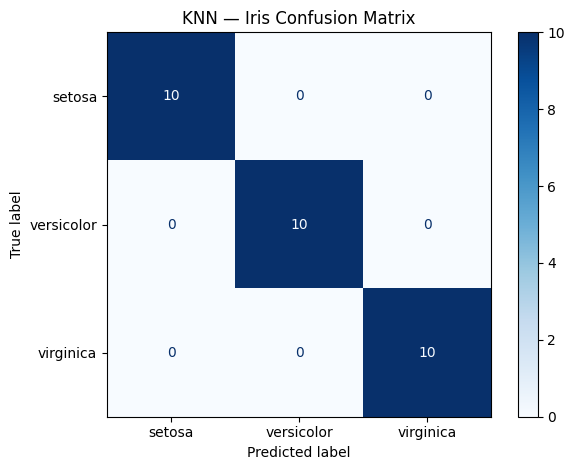

In [ ]:
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

#Accuracy
acc = accuracy_score(y_test, y_pred)
print(f'Test accuracy: {acc:.1%}')

#Confusion matrix (rows actual, columns predicted)
cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix (actual rows, predicted columns):')
print(cm)

# Display with class labels
disp = ConfusionMatrixDisplay(
confusion_matrix=cm,
display_labels=iris.target_names
)
disp.plot(cmap='Blues')
plt.title('KNN — Iris Confusion Matrix')
plt.tight_layout()
plt.savefig('confusion_matrix_knn.png', dpi=100)
plt.show()

# Markdown cell — interpret the matrix:
# 'Misclassifications: [list each off-diagonal cell].
# The model most commonly confuses [class A] with [class B] because...'


# Notebook: G5-MS-L06_classification_report.ipynb
**bold text**

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
X, y, test_size=0.2, random_state=42, stratify=y)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

print(classification_report(y_test, y_pred,
target_names=iris.target_names))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



#Write in a markdown cel for each class:
#'For class[X]:',
#'Precision = [Y]: when the model predicted[X], it was right[Y]% of the time.'
#'Recall = [Z]: of all actual [X] examples, the model found [Z]%.'
#'F1 = [W]: the balance between precision and recall'

Notebook: G5-MS-L07_experimentnotebookdispline.ipynb

In [ ]:
# Python ML Badge — Iris Flower Classification
## Understanding the Confusion Matrix and Classification Report

#**Author:** [BOLUWATISE OYETUNJI]
#**Date:** 19 October 2026
#**Course:** AI & AUTOMATION — Mindspire
#**Lesson:** L08 — classification_report in Full

#**Machine Learning Task:** Multiclass Classification
#**Algorithm:** K-Nearest Neighbors (KNN)
#**Dataset:** Iris Flower Dataset

# == CELL 2: Markdown — Research Question ==
#Can a K-Nearest Neighbors (KNN) machine learning model correctly identify the species
# of an Iris flower using its sepal length, sepal width, petal length, and petal width?

#How well does the model perform for each flower species
#when evaluated using a confusion matrix, precision,
#recall, F1-score, and accuracy?

# == CELL 3: Markdown — Hypothesis ==
#I predict that the KNN model will correctly classify
#at least 90% of the Iris flowers in the test dataset.

#I think this because different Iris flower species
#have different petal and sepal measurements.

#I also predict that Iris setosa will be easier to
#identify than the other two species.

#I will test my prediction using the confusion matrix
#and classification report.

# == CELL 4: Code — Imports ==
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import pandas as pd


# == CELL 5: Code — Data Loading and Exploration ==
# Load the Iris dataset
iris = load_iris()

X, y = iris.data, iris.target

# Create a DataFrame to explore the features
df = pd.DataFrame(X, columns=iris.feature_names)
df["species"] = y

# Display dataset shape
print("Dataset shape:", X.shape)

# Display the number of samples in each class
print("\nClass distribution:")
print(df["species"].value_counts().sort_index())

# Display the species names
print("\nTarget names:", iris.target_names)

# Preview the first five rows
print("\nFeature preview:")
print(df.head())

# == CELL 6: Code — Preprocessing + Split ==
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

# == CELL 7: Code — Model + Fit ==
# Create the KNN classifier
knn = KNeighborsClassifier(n_neighbors=5)

# Train the classifier using training data only
knn.fit(X_train, y_train)

# Predict the species of flowers in the test set
y_pred = knn.predict(X_test)

print("Model training completed!")
print("Predictions:", y_pred)

# == CELL 8: Code — Evaluation (confusion_matrix + classification_report) ==
# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("CONFUSION MATRIX")
print(cm)

# Calculate test accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nTEST ACCURACY")
print(f"{accuracy:.2%}")

# Display the classification report
print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)
# == CELL 9: Markdown — Results ==
## Results

#The KNN model achieved a test accuracy of 100%.

### Numerical Summary

#- Total dataset: 150 flowers
#- Training samples: 120
#- Testing samples: 30
#- Number of flower species: 3
#- Correct predictions: 30
#- Incorrect predictions: 0
#- Test accuracy: 100%

### Classification Report

#| Species | Precision | Recall | F1-score | Support |
#|---|---:|---:|---:|---:|
#| Setosa | 1.00 | 1.00 | 1.00 | 10 |
#| Versicolor | 1.00 | 1.00 | 1.00 | 10 |
#| Virginica | 1.00 | 1.00 | 1.00 | 10 |

### Confusion Matrix

#| Actual / Predicted | Setosa | Versicolor | Virginica |
#|---|---:|---:|---:|
#| Setosa | 10 | 0 | 0 |
#| Versicolor | 0 | 10 | 0 |
#| Virginica | 0 | 0 | 10 |

#The confusion matrix shows that all 30 flowers were
#classified correctly in this particular test.

# == CELL 10: Markdown — Interpretation ==
## Interpretation

#My hypothesis was supported by the test results.

#I predicted that the model would achieve at least
#90% accuracy, but it achieved 100% accuracy.

#The classification report showed that precision,
#recall, and F1-score were all 1.00 for each species.

#This means that the model made no incorrect predictions
#on the 30 test flowers.

#The confusion matrix also showed that all predictions
#were on the main diagonal, with no errors.

#I learned that accuracy tells us how many predictions
#were correct overall, while precision, recall, and
#F1-score help us understand performance for each class.

#However, 100% accuracy on one test set does not mean
#the model will always be perfect on new data.

# == CELL 11: Markdown — Ethics ==
# ## Ethics Question
# 'If this model were deployed, who would it affect?
# What are the bias risks in the training data?
# Which class is most likely to be misclassified, and what is the real-world impact?'
## Ethics Question

#What could happen if we trusted a machine learning
#model without checking whether its predictions were
#accurate and reliable?

## My Answer

#A machine learning model can sometimes make mistakes,
#even when it performs very well during testing.

#If people trust every prediction without checking,
#they might make wrong decisions. For example, a model
#used to identify harmful plants could give incorrect
#information and put people at risk.

#We should test machine learning models carefully,
#use suitable data, and allow people to review
#important decisions.

#I also learned that a model should not be trusted
#only because it achieved high accuracy on one dataset.

# == CELL 12: Markdown — Conclusion ==
# ## Conclusion and Next Steps
# [One sentence conclusion. One sentence on what to try next.]
## Conclusion

#In this project, I trained a K-Nearest Neighbors
#classifier to predict Iris flower species using
#four flower measurements.

#The model correctly classified all 30 flowers in
#the test dataset and achieved 100% test accuracy.

#I learned how to:
#1. Load and explore a dataset.
#2. Divide data into training and testing sets.
#3. Train a classification model.
#4. Make predictions using test data.
#5. Interpret a confusion matrix.
#6. Read precision, recall, F1-score, and accuracy.
#7. Evaluate a hypothesis using experimental results.

## Next Steps

#I would like to:
#1. Test different values of K, such as 3, 7, and 9.
#2. Compare KNN with another classification algorithm.
#3. Learn how feature scaling affects KNN predictions.
#4. Use cross-validation to check whether the model
  # performs consistently across different data splits.
#5. Try predicting the species of a new Iris flower.

## Final Reflection

#I learned that building a machine learning model
#is not only about making predictions. It is also
#important to evaluate the predictions and understand
#whether the model can be trusted.

Dataset shape: (150, 4)

Class distribution:
species
0    50
1    50
2    50
Name: count, dtype: int64

Target names: ['setosa' 'versicolor' 'virginica']

Feature preview:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

   species  
0        0  
1        0  
2        0  
3        0  
4        0  
Training samples: 120
Testing samples: 30

Training class distribution:
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
0    10
1    10
2    10
Name: count, dtype: int64
Model training completed!
Predictions: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 

LO9

In [3]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Without scaling
knn_raw = KNeighborsClassifier(n_neighbors=5)
knn_raw.fit(X_train, y_train)
acc_raw = accuracy_score(y_test, knn_raw.predict(X_test))
print(f'KNN (no scaling):   {acc_raw:.1%}')

# With scaling — always use a Pipeline to prevent leakage
knn_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('knn',    KNeighborsClassifier(n_neighbors=5))
])
knn_scaled.fit(X_train, y_train)
acc_scaled = accuracy_score(y_test, knn_scaled.predict(X_test))
print(f'KNN (with scaling): {acc_scaled:.1%}')

# Print full report
print(classification_report(y_test, knn_scaled.predict(X_test),
                             target_names=iris.target_names))

KNN (no scaling):   100.0%
KNN (with scaling): 93.3%
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



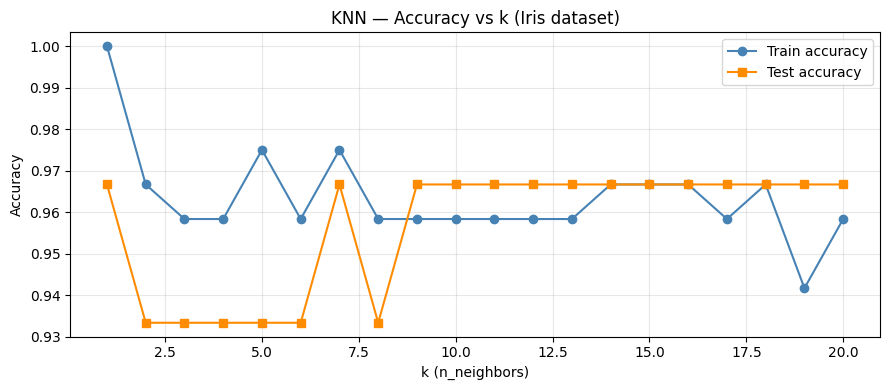

Best k: 1  |  Test accuracy: 96.7%


In [4]:
# Vary k from 1 to 20 and plot train and test accuracy
k_values = range(1, 21)
train_accs, test_accs = [], []

for k in k_values:
    pipe = Pipeline([('sc', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=k))])
    pipe.fit(X_train, y_train)
    train_accs.append(accuracy_score(y_train, pipe.predict(X_train)))
    test_accs.append(accuracy_score(y_test,  pipe.predict(X_test)))

plt.figure(figsize=(9, 4))
plt.plot(k_values, train_accs, 'o-', label='Train accuracy', color='steelblue')
plt.plot(k_values, test_accs,  's-', label='Test accuracy',  color='darkorange')
plt.xlabel('k (n_neighbors)'); plt.ylabel('Accuracy')
plt.title('KNN — Accuracy vs k (Iris dataset)')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig('knn_k_comparison.png', dpi=100); plt.show()

best_k = k_values[test_accs.index(max(test_accs))]
print(f'Best k: {best_k}  |  Test accuracy: {max(test_accs):.1%}')

# Write in notebook:
# 'At k=1: train accuracy=[X], test accuracy=[Y]. Gap=[Z%] — this indicates overfitting.'
# 'Best k=[W]. Above k=[P] the accuracy decreases because...'